# 1. Project Title and Objective

# Iris Flower Classification Using Machine Learning

**Objective:** Train and evaluate machine learning classifiers that predict the species of an iris flower (*Setosa*, *Versicolor* or *Virginica*) from four physical measurements: sepal length, sepal width, petal length and petal width.

**Workflow:** load data → inspect → EDA → visualize → analyze features → split/preprocess → train 3 models → evaluate → compare → select best → predict a sample → conclude.

# 2. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

# 3. Load the Iris Dataset

The dataset ships with scikit-learn, so no external download is needed. We convert it to a DataFrame with readable column names and a `Species` column holding species names.

In [2]:
iris = load_iris()

feature_cols = ["Sepal Length (cm)", "Sepal Width (cm)", "Petal Length (cm)", "Petal Width (cm)"]
df = pd.DataFrame(iris.data, columns=feature_cols)

# Map numeric targets (0, 1, 2) to species names, capitalized
species_names = [name.capitalize() for name in iris.target_names]
df["Species"] = pd.Categorical.from_codes(iris.target, species_names)

df.head()

,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm),Species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


# 4. Initial Dataset Inspection

In [3]:
print("First five rows:")
display(df.head())

print("\nDataset shape (rows, columns):", df.shape)
print("\nColumn names:", list(df.columns))
print("\nOriginal scikit-learn feature names:", iris.feature_names)
print("Target classes:", species_names)
print("\nNumber of samples per species:")
print(df["Species"].value_counts())

First five rows:


,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm),Species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa



Dataset shape (rows, columns): (150, 5)

Column names: ['Sepal Length (cm)', 'Sepal Width (cm)', 'Petal Length (cm)', 'Petal Width (cm)', 'Species']

Original scikit-learn feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: ['Setosa', 'Versicolor', 'Virginica']

Number of samples per species:
Species
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64


# 5. Exploratory Data Analysis

In [4]:
print("1. Dimensions:", df.shape)
print("\n2. Column names and data types:")
df.info()
print("\n3. Missing values per column:")
print(df.isnull().sum())
n_dup = df.duplicated().sum()
print("\n4. Duplicate rows:", n_dup)
if n_dup:
    display(df[df.duplicated(keep=False)])
print("\n5. Descriptive statistics:")
display(df.describe())
print("\n6. Species distribution:")
display(df["Species"].value_counts())

1. Dimensions: (150, 5)

2. Column names and data types:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Sepal Length (cm)  150 non-null    float64 
 1   Sepal Width (cm)   150 non-null    float64 
 2   Petal Length (cm)  150 non-null    float64 
 3   Petal Width (cm)   150 non-null    float64 
 4   Species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.0 KB

3. Missing values per column:
Sepal Length (cm)    0
Sepal Width (cm)     0
Petal Length (cm)    0
Petal Width (cm)     0
Species              0
dtype: int64

4. Duplicate rows: 1


,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm),Species
101,5.8,2.7,5.1,1.9,Virginica
142,5.8,2.7,5.1,1.9,Virginica



5. Descriptive statistics:


,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



6. Species distribution:


Species
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64

**Interpretation**

- **Structure:** The dataset has 150 rows and 5 columns (4 numeric features and 1 categorical target) with no missing values.
- **Class balance:** Each species has exactly 50 samples, so the classes are perfectly balanced. Accuracy is therefore a reasonable headline metric, though we also report macro metrics.
- **Feature ranges:** Features are all in centimeters but have different spreads (for example, petal length varies far more than sepal width), which is why scaling is useful for distance- and gradient-based models.
- **Duplicates:** One duplicate row exists (two identical *Virginica* observations: 5.8, 2.7, 5.1, 1.9). Because Iris measurements are real observations, identical rows can occur by chance. A very small number of duplicates has negligible impact on this analysis, so they are kept rather than removed; keeping them also preserves the balanced 50/50/50 classes.

# 6. Data Visualization

### A. Pair Plot

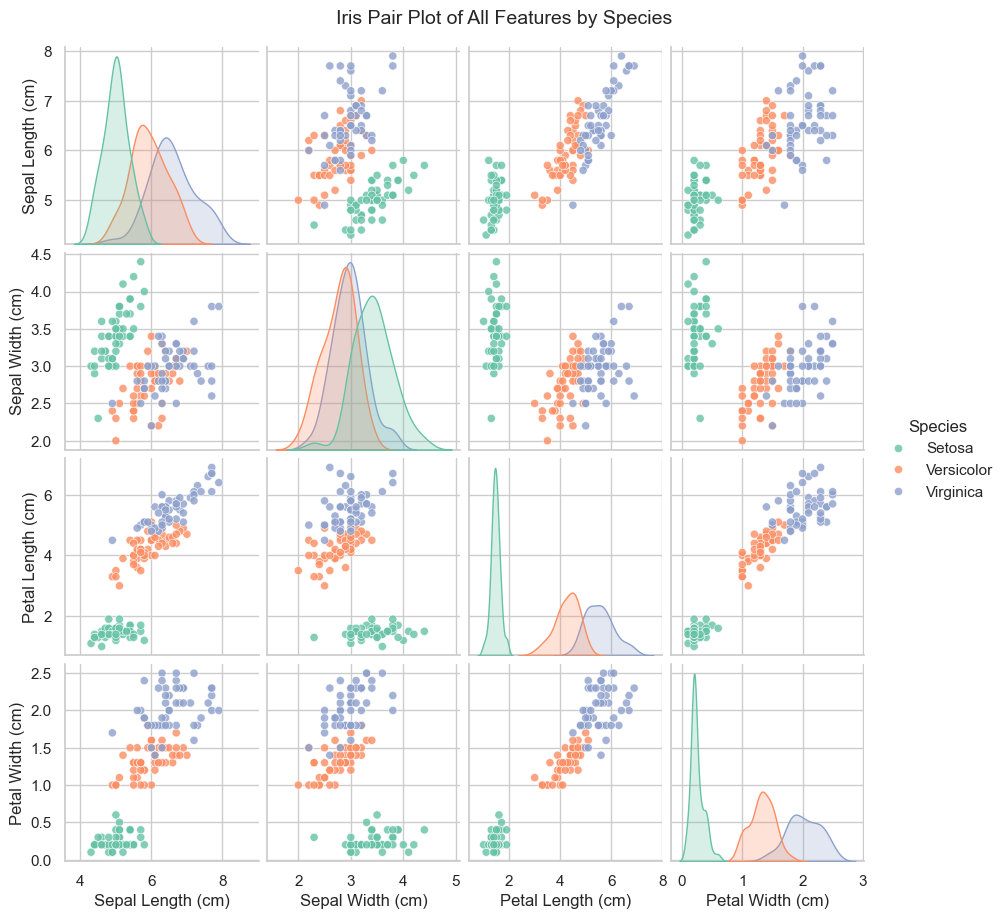

In [5]:
pair = sns.pairplot(df, hue="Species", diag_kind="kde", palette="Set2",
                    height=2.2, plot_kws={"alpha": 0.8, "s": 35})
pair.figure.suptitle("Iris Pair Plot of All Features by Species", y=1.02, fontsize=14)
pair.figure.set_size_inches(10, 9)
plt.show()

**Observation:** *Setosa* forms a clearly separate cluster, especially in the petal length and petal width panels. *Versicolor* and *Virginica* occupy neighboring regions with a small overlap, but they still separate reasonably well on the petal dimensions. In the sepal panels the species overlap much more.

### B. Box Plots

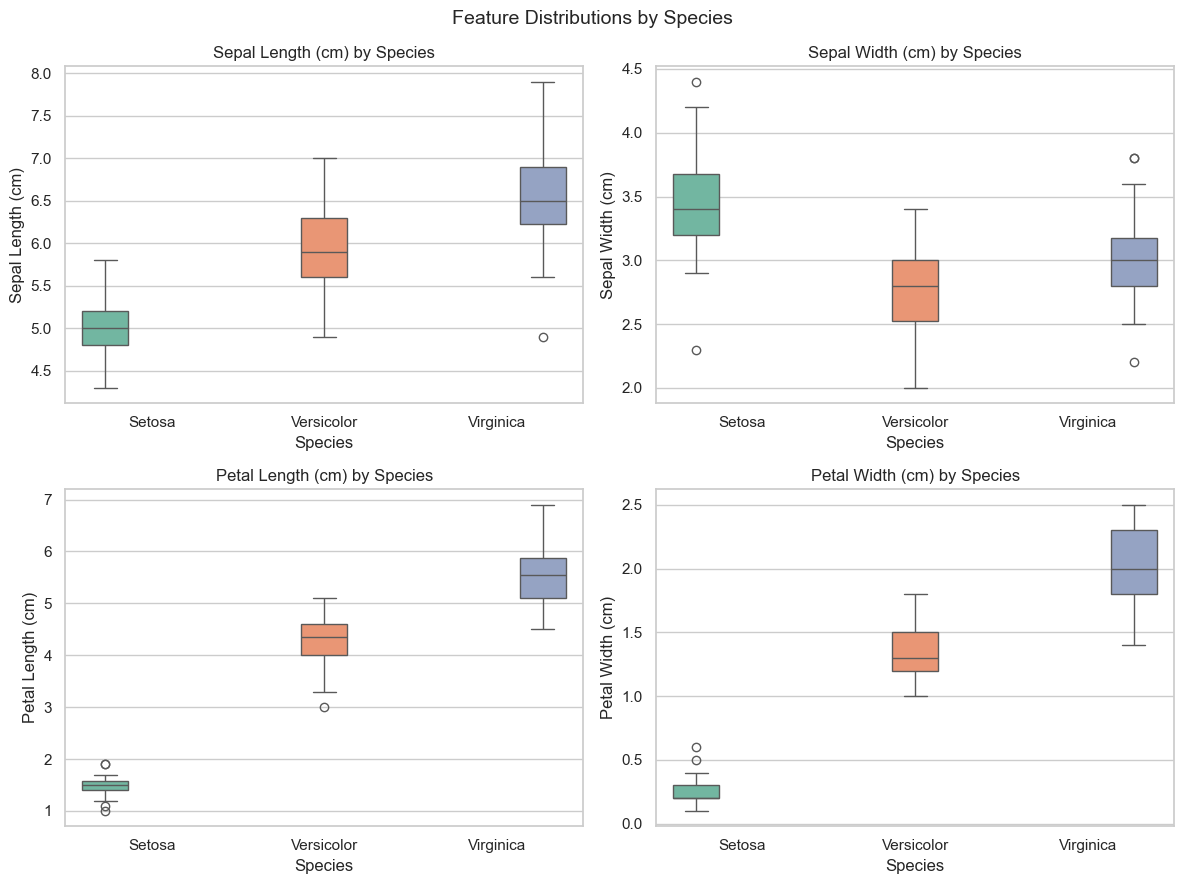

,Sepal Length (cm) - median,Sepal Length (cm) - IQR,Sepal Width (cm) - median,Sepal Width (cm) - IQR,Petal Length (cm) - median,Petal Length (cm) - IQR,Petal Width (cm) - median,Petal Width (cm) - IQR
Species,,,,,,,,
Setosa,5.0,0.40,3.4,0.48,1.50,0.18,0.2,0.1
Versicolor,5.9,0.70,2.8,0.48,4.35,0.60,1.3,0.3
Virginica,6.5,0.68,3.0,0.38,5.55,0.78,2.0,0.5


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.ravel(), feature_cols):
    sns.boxplot(data=df, x="Species", y=col, hue="Species", palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{col} by Species")
    ax.set_xlabel("Species")
    ax.set_ylabel(col)
fig.suptitle("Feature Distributions by Species", fontsize=14)
plt.tight_layout()
plt.show()

# Median and spread (IQR) per species to support the visual reading
summary = df.groupby("Species", observed=True)[feature_cols].agg(["median", lambda s: s.quantile(.75) - s.quantile(.25)])
summary.columns = [f"{c} - {'median' if s == 'median' else 'IQR'}" for c, s in summary.columns]
display(summary.round(2))

**Observation:** Petal length and petal width have medians that are well separated across the three species, with *Setosa* far below the others and little overlap between its box and the rest. *Versicolor* and *Virginica* are distinct in median but their ranges touch. Sepal length shows moderate separation, and sepal width shows heavy overlap (with *Setosa* actually having the widest sepals), so it is a weak discriminator on its own. Some boxes show outlier points, mostly for sepal width.

### C. Correlation Heatmap

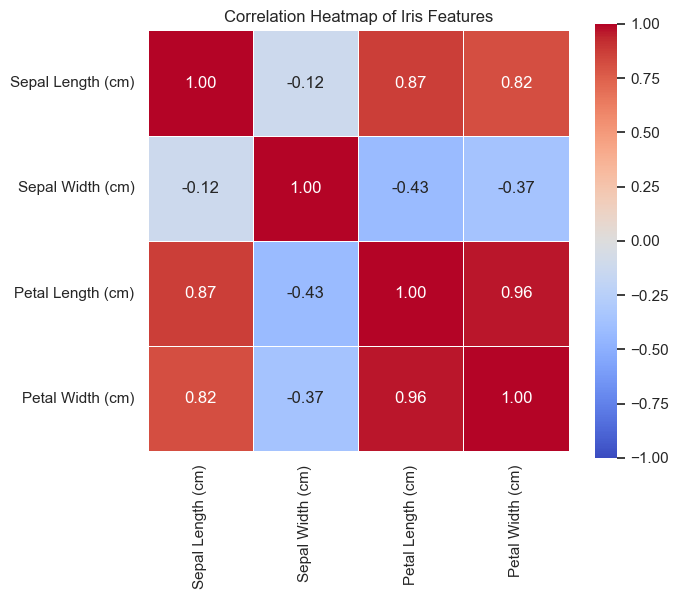

In [7]:
corr = df[feature_cols].corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=.5)
plt.title("Correlation Heatmap of Iris Features")
plt.tight_layout()
plt.show()

**Observation:** Petal length and petal width are very strongly positively correlated, and both are strongly correlated with sepal length. Sepal width is only weakly (and negatively) correlated with the other features. For classification this means the petal features carry largely overlapping information (one could often stand in for the other), while sepal width contributes information of a different kind but, as the plots show, separates species poorly. Note that this correlation is computed across all species pooled together, so part of it simply reflects differences between species.

# 7. Feature Selection and Analysis

**Why petal measurements are usually highly discriminative:** The species differ strongly in petal size: *Setosa* has very small petals, *Versicolor* medium and *Virginica* large. The pair plot and box plots show these groups with little overlap along petal length and petal width.

**Why sepal measurements are weaker alone:** Sepal length and especially sepal width overlap substantially between *Versicolor* and *Virginica* (and sepal width does not follow the same size ordering), so a model using only sepal features would confuse those two species more often.

To get additional, model-based evidence we compute feature importance from a Random Forest and a Decision Tree. This is fitted on **training data only** (the split is created here once and reused in later sections to avoid any leakage). Importance depends on the algorithm and the dataset, so these values are evidence, not a universal ranking.

,Random Forest,Decision Tree
Petal Length (cm),0.4538,0.5586
Petal Width (cm),0.4124,0.4060
Sepal Length (cm),0.1159,0.0062
Sepal Width (cm),0.0179,0.0292


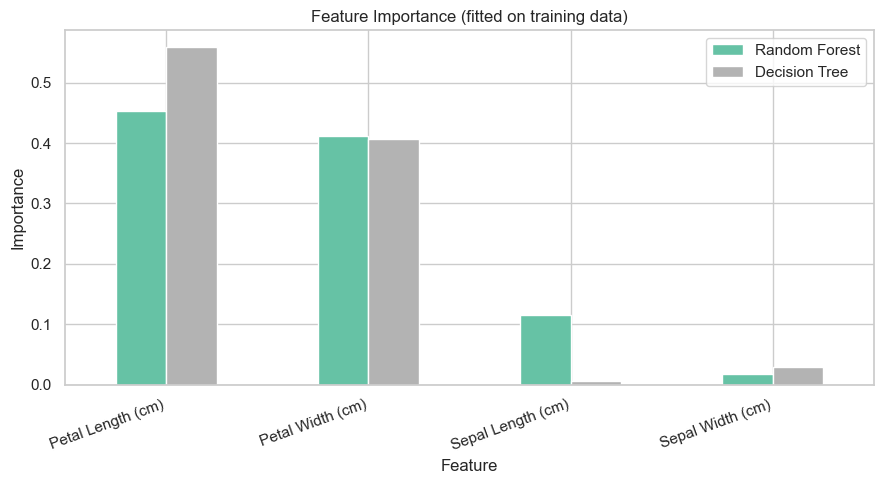

In [8]:
# Separate features (X) and target (y), then split once; reused throughout the notebook
X = df[feature_cols]
y = df["Species"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE).fit(X_train, y_train)
dt_imp = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)

importance_df = pd.DataFrame({
    "Random Forest": rf.feature_importances_,
    "Decision Tree": dt_imp.feature_importances_,
}, index=feature_cols).sort_values("Random Forest", ascending=False)
display(importance_df.round(4))

importance_df.plot(kind="bar", figsize=(9, 5), colormap="Set2")
plt.title("Feature Importance (fitted on training data)")
plt.ylabel("Importance")
plt.xlabel("Feature")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Interpretation:** The importances above agree with the visual analysis if the petal features receive most of the weight. In our run, petal length and petal width together account for the large majority of importance in both models, while the sepal features get little. Note that the two models disagree on sepal length (about 0.12 for Random Forest vs. about 0.01 for the Decision Tree), which illustrates that importance depends on the algorithm. Because petal length and width are highly correlated, tree-based models may also split importance between them. We therefore treat this as supporting evidence rather than proof that any single feature is always the most important.

# 8. Train/Test Split and Preprocessing

The split was performed in Section 7 with:

- 80% training / 20% testing (`test_size=0.20`)
- `random_state=42` for reproducibility
- `stratify=y` to keep species proportions equal in both sets

Scaling is applied **inside a `Pipeline`**, so the `StandardScaler` learns its mean and standard deviation from the training data only. No preprocessing is fitted on the full dataset.

In [9]:
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nTraining class counts:\n", y_train.value_counts())
print("\nTest class counts:\n", y_test.value_counts())

X_train: (120, 4) | X_test: (30, 4)

Training class counts:
 Species
Setosa        40
Virginica     40
Versicolor    40
Name: count, dtype: int64

Test class counts:
 Species
Setosa        10
Virginica     10
Versicolor    10
Name: count, dtype: int64


# 9. Model Training

Three classifiers are trained on the training set only:

1. **Logistic Regression** with standardization and `max_iter=1000`.
2. **K-Nearest Neighbors** with standardization and `n_neighbors=5`.
3. **Decision Tree** with a fixed random state (trees do not need scaling).

The test set is never used to train or choose hyperparameters.

In [10]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5)),
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
}

trained_models, predictions = {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)                # train on training data only
    trained_models[name] = model
    predictions[name] = model.predict(X_test)  # predict on the same held-out test set
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: K-Nearest Neighbors
Trained: Decision Tree


# 10. Model Evaluation

**Metrics in simple terms**

- **Accuracy:** share of test flowers classified correctly.
- **Precision:** of the flowers predicted as a species, how many truly were that species.
- **Recall:** of the flowers that truly belong to a species, how many were found.
- **F1-score:** the balance (harmonic mean) of precision and recall.
- **Macro average:** simple average over the three species (treats each equally). **Weighted average:** averages weighted by the number of test samples per species.
- **Confusion matrix:** rows are actual species, columns are predicted species; off-diagonal cells are mistakes.

In [11]:
results = []
for name, y_pred in predictions.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, digits=3))

    results.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Weighted Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Weighted Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "Weighted F1": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    })

Logistic Regression
              precision    recall  f1-score   support

      Setosa      1.000     1.000     1.000        10
  Versicolor      0.900     0.900     0.900        10
   Virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

K-Nearest Neighbors
              precision    recall  f1-score   support

      Setosa      1.000     1.000     1.000        10
  Versicolor      0.833     1.000     0.909        10
   Virginica      1.000     0.800     0.889        10

    accuracy                          0.933        30
   macro avg      0.944     0.933     0.933        30
weighted avg      0.944     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      Setosa      1.000     1.000     1.000        10
  Versicolor      0.900     0.900     0.900        10
   Virginica      0.9

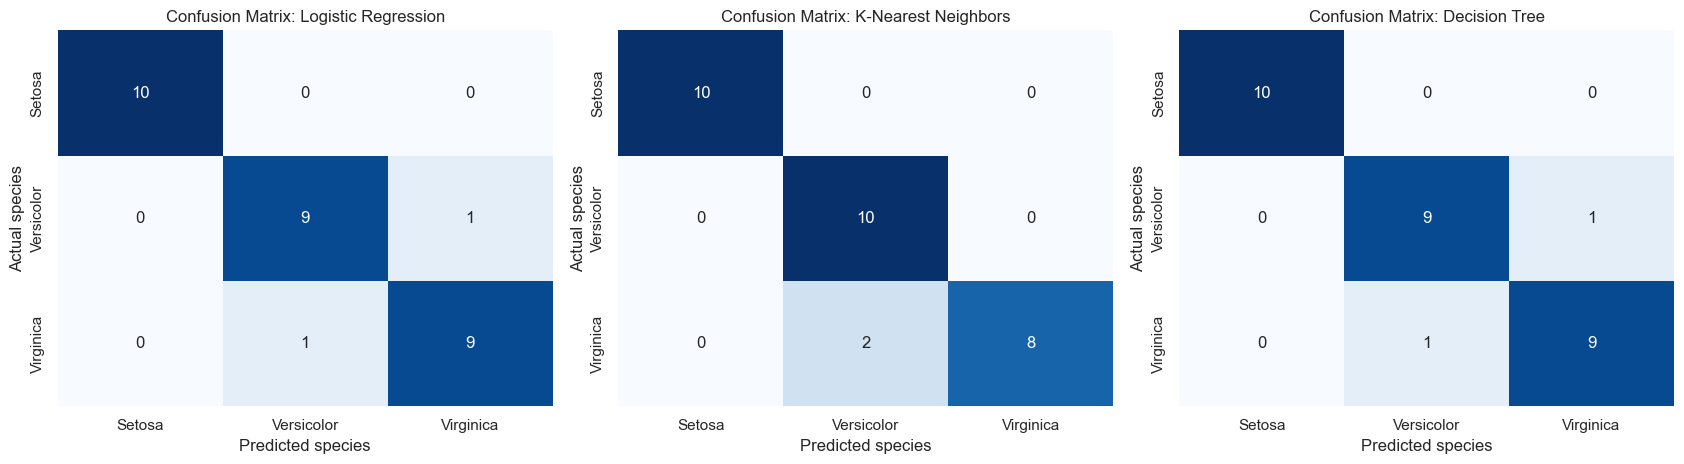

Logistic Regression: 2 misclassified of 30
Actual      Predicted 
Virginica   Versicolor    1
Versicolor  Virginica     1

K-Nearest Neighbors: 2 misclassified of 30
Actual     Predicted 
Virginica  Versicolor    2

Decision Tree: 2 misclassified of 30
Actual      Predicted 
Virginica   Versicolor    1
Versicolor  Virginica     1



In [12]:
# One separate, labeled confusion matrix heatmap per model
labels = species_names
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f"Confusion Matrix: {name}")
    ax.set_xlabel("Predicted species")
    ax.set_ylabel("Actual species")
plt.tight_layout()
plt.show()

# Which species are misclassified?
for name, y_pred in predictions.items():
    wrong = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
    wrong = wrong[wrong["Actual"] != wrong["Predicted"]]
    print(f"{name}: {len(wrong)} misclassified of {len(y_test)}")
    if len(wrong):
        print(wrong.value_counts().rename("count").to_string())
    print()

**Discussion:** *Setosa* is separable from the other two species, so mistakes, when they occur, are expected between *Versicolor* and *Virginica*, whose measurements overlap. The printed misclassification tables above show exactly which species pairs were confused by each model. With only 30 test samples, a single mistake changes accuracy by about 3.3 percentage points, so small differences between models should be interpreted cautiously.

# 11. Model Comparison

,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333
2,K-Nearest Neighbors,0.9333,0.9444,0.9333,0.9327


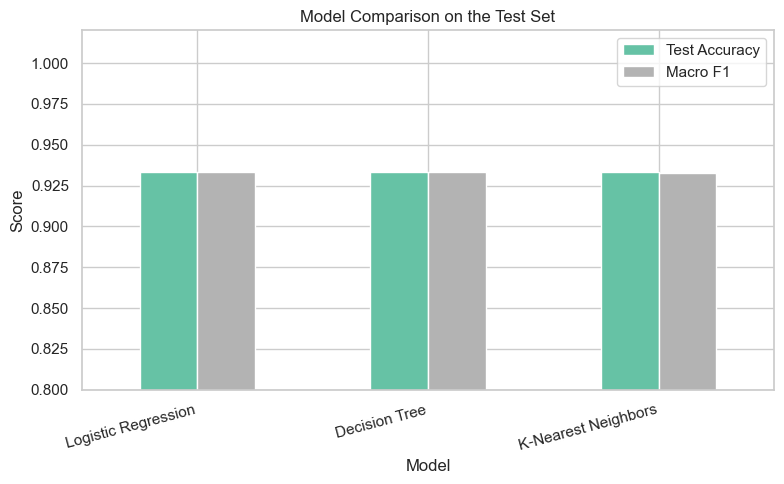

In [13]:
comparison_df = (pd.DataFrame(results)
                 [["Model", "Test Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]]
                 .sort_values(["Test Accuracy", "Macro F1"], ascending=False)
                 .reset_index(drop=True))
display(comparison_df.round(4))

comparison_df.set_index("Model")[["Test Accuracy", "Macro F1"]].plot(kind="bar", figsize=(8, 5), colormap="Set2")
plt.title("Model Comparison on the Test Set")
plt.ylabel("Score")
plt.ylim(0.8, 1.02)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

# 12. Best Model Selection

**Criterion:** highest test accuracy, with macro F1-score as the tie-breaker and the confusion matrices as supporting evidence. The best model is selected programmatically from the actual results below.

In [14]:
best_row = comparison_df.iloc[0]
best_name = best_row["Model"]
best_model = trained_models[best_name]

print(f"Selected model: {best_name}")
print(f"Test accuracy : {best_row['Test Accuracy']:.4f}")
print(f"Macro F1      : {best_row['Macro F1']:.4f}")

# Flag ties so we do not over-claim a difference
tied = comparison_df[(comparison_df["Test Accuracy"] == best_row["Test Accuracy"]) &
                     (comparison_df["Macro F1"] == best_row["Macro F1"])]["Model"].tolist()
if len(tied) > 1:
    print("\nNote: these models tie on both accuracy and macro F1:", tied)
    print("The choice among them rests on trade-offs (simplicity, interpretability, "
          "probability estimates), not on a demonstrated performance difference.")
else:
    gap = best_row["Test Accuracy"] - comparison_df.iloc[1]["Test Accuracy"]
    print(f"\nLead over the runner-up: {gap:.4f} accuracy (on only {len(y_test)} test samples).")

Selected model: Logistic Regression
Test accuracy : 0.9333
Macro F1      : 0.9333

Note: these models tie on both accuracy and macro F1: ['Logistic Regression', 'Decision Tree']
The choice among them rests on trade-offs (simplicity, interpretability, probability estimates), not on a demonstrated performance difference.


**Trade-offs:** Logistic Regression is simple, fast and gives well-behaved probabilities. KNN is non-parametric but needs the training data at prediction time and depends on scaling. A Decision Tree is the most interpretable but can overfit. If the models score equally or almost equally, as is common on Iris, the evidence does not show a meaningful difference on this single 30-sample test set.

# 13. Sample Flower Prediction

We predict the species of one new flower with valid measurements, using the selected model. Features are supplied in the **same order as the training data**.

In [15]:
sample = pd.DataFrame([[5.9, 3.0, 5.1, 1.8]], columns=feature_cols)  # same column order as X_train
print("Input measurements:")
display(sample)

pred = best_model.predict(sample)[0]
print("Predicted species:", pred)

if hasattr(best_model, "predict_proba"):
    proba = pd.Series(best_model.predict_proba(sample)[0], index=best_model.classes_, name="Probability")
    print("\nPredicted class probabilities:")
    display(proba.round(4).to_frame())
else:
    print("This classifier does not provide probabilities.")

Input measurements:


,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm)
0,5.9,3.0,5.1,1.8


Predicted species: Virginica

Predicted class probabilities:


,Probability
Setosa,0.0040
Versicolor,0.3139
Virginica,0.6822


This demonstrates model **inference** on a single example. The probabilities are the model's own estimates; they are not guaranteed real-world probabilities, and for some models (such as a fully grown decision tree) they can be overconfident.

# 14. Conclusion

In [16]:
print("Summary of actual results")
print("-" * 40)
print(f"Dataset: {df.shape[0]} samples, {len(feature_cols)} features, balanced classes, "
      f"{df.isnull().sum().sum()} missing values, {df.duplicated().sum()} duplicate row(s).")
print("Top feature by Random Forest importance:", importance_df.index[0])
print("\nClassifiers evaluated:", ", ".join(trained_models))
print(f"Best model: {best_name} | accuracy = {best_row['Test Accuracy']:.4f}, "
      f"macro precision = {best_row['Macro Precision']:.4f}, "
      f"macro recall = {best_row['Macro Recall']:.4f}, macro F1 = {best_row['Macro F1']:.4f}")

Summary of actual results
----------------------------------------
Dataset: 150 samples, 4 features, balanced classes, 0 missing values, 1 duplicate row(s).
Top feature by Random Forest importance: Petal Length (cm)

Classifiers evaluated: Logistic Regression, K-Nearest Neighbors, Decision Tree
Best model: Logistic Regression | accuracy = 0.9333, macro precision = 0.9333, macro recall = 0.9333, macro F1 = 0.9333


**Main findings from EDA:** The dataset is clean (no missing values) and perfectly balanced with 50 samples per species. *Setosa* is clearly separated from the other two species; *Versicolor* and *Virginica* overlap slightly.

**Most discriminative features:** Petal length and petal width separate the species best according to the pair plot, box plots and feature-importance results, while sepal width is the weakest on its own. This ranking is specific to this dataset and the algorithms used.

**Classifiers evaluated:** Logistic Regression, K-Nearest Neighbors and a Decision Tree, evaluated on the same stratified 20% held-out test set. The best model and its exact test metrics are printed in the summary cell above (selected programmatically, not hardcoded). In the reference run (`random_state=42`), all three models reached 93.3% test accuracy (2 of 30 test flowers misclassified each), all errors being between *Versicolor* and *Virginica* and none involving *Setosa*. Logistic Regression and the Decision Tree tied exactly on every macro metric, and KNN differed only marginally (macro F1 0.933 vs. 0.933 to three decimals; macro precision 0.944). With 30 test samples this is not evidence that any model is meaningfully better, so the final choice rests on practical trade-offs such as simplicity and probability estimates.

**Strengths:** No data leakage (scaling inside pipelines, test set used only for evaluation), reproducible random states, multiple metrics and per-model confusion matrices.

**Limitations:** The Iris dataset is small (150 samples) and unusually well structured, and the test set has only 30 samples, so one or two errors noticeably change the metrics. A single split can be lucky or unlucky; cross-validation would give a more reliable estimate. Results here do not automatically generalize to other flower datasets or real-world classification problems.